In [ ]:
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import pyvista as pv
from scipy.interpolate import RegularGridInterpolator
from matplotlib.widgets import Slider
import warnings
warnings.filterwarnings('ignore')

class NiftiMeshOverlay:
    def __init__(self, nifti_path, mesh_path):
        """
        Initialize with NIfTI file and mesh file paths.
        
        Parameters:
        nifti_path: str - path to NIfTI file (.nii or .nii.gz)
        mesh_path: str - path to mesh file (.ply, .stl, .obj, .vtk, etc.)
        """
        origin=self.load_nifti(nifti_path)
        self.load_mesh(mesh_path, origin)
        self.setup_interpolator()
    
    def load_nifti(self, nifti_path):
        """Load NIfTI file and extract volume data."""
        self.nifti_img = nib.load(nifti_path)
        self.volume_data = self.nifti_img.get_fdata()
        self.affine = self.nifti_img.affine
        self.header = self.nifti_img.header
        origin = self.affine[:3, 3]
        #origin=[0,0,0]
        # Get voxel dimensions
        self.voxel_sizes = self.header.get_zooms()[:3]
        
        # Create coordinate grids
        shape = self.volume_data.shape
        self.x_coords = np.arange(shape[0]) * self.voxel_sizes[0]
        self.y_coords = np.arange(shape[1]) * self.voxel_sizes[1]
        self.z_coords = np.arange(shape[2]) * self.voxel_sizes[2]
        
        #print(f"NIfTI volume shape: {self.volume_data.shape}")
        #print(f"Voxel sizes: {self.voxel_sizes}")
        
        # Create PyVista ImageData for volume
        self.volume_pv = pv.ImageData(dimensions=shape, 
                                     spacing=self.voxel_sizes,
                                     origin=[0,0,0])
        self.volume_pv.point_data["values"] = self.volume_data.flatten(order='F')
        print("PyVista IMAGE bounds:", self.volume_pv.bounds)
        return origin
    def load_mesh(self, mesh_path, origin=None, flip=True):
        """Load mesh file using PyVista."""        
        self.mesh = pv.read(mesh_path)
       
        if isinstance(self.mesh, pv.UnstructuredGrid):
            self.mesh = self.mesh.extract_surface()        
        if flip: 
            self.mesh.points[:, 0] = -self.mesh.points[:, 0]
            self.mesh.points[:, 1] = -self.mesh.points[:, 1]
        if origin is not None: 
            self.mesh.points[:, 0] += origin[0]
            self.mesh.points[:, 1] += origin[1]
            self.mesh.points[:, 2] -= origin[2]
        #print(f"Mesh loaded: {self.mesh.n_points} points, {self.mesh.n_cells} cells")
       
        print(f"New bounds: {self.mesh.bounds}")

    def setup_interpolator(self):
        """Setup interpolator for sampling volume data at arbitrary points."""
        self.interpolator = RegularGridInterpolator(
            (self.x_coords, self.y_coords, self.z_coords),
            self.volume_data,
            method='linear',
            bounds_error=False,
            fill_value=0
        )
    
    def slice_volume(self, axis, slice_idx):
        """
        Extract a 2D slice from the volume.
        
        Parameters:
        axis: int - axis to slice along (0=sagittal, 1=coronal, 2=axial)
        slice_idx: int - index of the slice
        """
        if axis == 0:  # Sagittal
            return self.volume_data[slice_idx, :, :]
        elif axis == 1:  # Coronal
            return self.volume_data[:, slice_idx, :]
        elif axis == 2:  # Axial
            return self.volume_data[:, :, slice_idx]
    
    def slice_mesh_with_plane(self, plane_origin, plane_normal):
        """
        Slice mesh with a plane using PyVista.
        
        Parameters:
        plane_origin: array-like - point on the plane
        plane_normal: array-like - normal vector of the plane
        """
        try:
            # Slice the mesh directly without creating a separate plane object
            sliced = self.mesh.slice(normal=plane_normal, origin=plane_origin)
            return sliced
        except Exception as e:
            print(f"Could not slice mesh with plane: {e}")
            return None
    
    def sample_volume_on_mesh(self):
        """Sample volume data at mesh vertex positions."""
        # Sample volume data at mesh points
        mesh_points = self.mesh.points
        vertex_values = self.interpolator(mesh_points)
        
        # Add values to mesh
        self.mesh.point_data["volume_values"] = vertex_values
        return vertex_values
    
    def plot_pyvista_slice(self, slice_idx=None, show_mesh=True, opacity=0.7, plane="axial"):
        """
        Create PyVista visualization with volume slice and mesh.
        
        Parameters:
        slice_idx: int - axial slice index (default: middle slice)
        show_mesh: bool - whether to show the mesh
        opacity: float - mesh opacity
        """
        shape = self.volume_data.shape
        # Pick default slice index if not provided
        if slice_idx is None:
            if plane == "axial":
                slice_idx = shape[2] // 2
            elif plane == "sagittal":
                slice_idx = shape[0] // 2
            elif plane == "coronal":
                slice_idx = shape[1] // 2
        print(slice_idx)
        # Map orientation → normal vector & slice position
        if plane == "axial":
            plane_normal = [0, 0, 1]
            position = slice_idx * self.voxel_sizes[2]
            plane_origin = [self.x_coords.mean(), self.y_coords.mean(), position]
            bounds=[self.x_coords.min(), self.x_coords.max(),self.y_coords.min(), self.y_coords.max(), position, position+10]
        elif plane == "sagittal":
            plane_normal = [1, 0, 0]
            position = slice_idx * self.voxel_sizes[0]
            plane_origin = [position, self.y_coords.mean(), self.z_coords.mean()]
            bounds=[position, position+10, self.y_coords.min(), self.y_coords.max(), self.z_coords.min(), self.z_coords.max()]

        elif plane == "coronal":
            plane_normal = [0, 1, 0]
            position = slice_idx * self.voxel_sizes[1]
            plane_origin = [self.x_coords.mean(), position, self.z_coords.mean()]
            bounds=[self.x_coords.min(), self.x_coords.max(),position, position+10, self.z_coords.min(), self.z_coords.max()]
            
        else:
            raise ValueError("plane must be 'axial', 'sagittal', or 'coronal'")
        # Create plotter
        #plotter = pv.Plotter(shape=(1, 2), window_size=(1200, 600))
        plotter = pv.Plotter(window_size=(600, 600))
        # Left panel: Volume slice only
        #plotter.subplot(0, 0)
        z_position = slice_idx * self.voxel_sizes[2]
        
        # Create slice plane
        #plane_origin = [self.x_coords.mean(), self.y_coords.mean(), z_position]
        #plane_normal = [0, 0, 1]
        
        # Slice the image volume
        volume_slice = self.volume_pv.slice(normal=plane_normal, origin=plane_origin)
        #plotter.add_mesh(volume_slice, scalars='values', cmap='gray', 
#                        show_scalar_bar=True, scalar_bar_args={'title': 'Volume Intensity'})
        #plotter.add_title(f"Volume Slice at z={z_position:.1f}mm")
        
        # Right panel: Volume + Mesh overlay
        #plotter.subplot(0, 1)
        plotter.add_mesh(volume_slice, scalars='values', cmap='gray', 
                        opacity=1, show_scalar_bar=False)
        
        full_mesh=False # full mesh or clip mesh 
        if show_mesh:
            if full_mesh: 
                # Add full mesh with transparency
                mesh_copy = self.mesh.copy()
                plotter.add_mesh(mesh_copy, color='red', opacity=opacity, 
                            show_edges=False, lighting=True)
            else: # Add clipped mesh 
                clipped_mesh=self.mesh.clip_box(bounds=()) 

            # Add mesh slice if it exists
            mesh_slice = self.slice_mesh_with_plane(plane_origin, plane_normal)
            if mesh_slice and mesh_slice.n_points > 0:
                plotter.add_mesh(mesh_slice, color='yellow', line_width=3, 
                               render_lines_as_tubes=True)
        
        plotter.add_title("Volume + Mesh Overlay")
        
        # Set camera and show
        #plotter.link_views()
        plotter.view_xy()
        plotter.show()
    
    def plot_3d_overlay(self, volume_threshold=None, mesh_opacity=0.7):
        """
        Create full 3D visualization with volume rendering and mesh.
        
        Parameters:
        volume_threshold: float - threshold for volume rendering
        mesh_opacity: float - mesh opacity
        """
        plotter = pv.Plotter()
        
        # Add volume rendering if threshold is provided
        if volume_threshold is not None:
            # Threshold the volume
            volume_thresh = self.volume_pv.threshold(volume_threshold)
            plotter.add_mesh(volume_thresh, scalars='values', cmap='viridis',
                           opacity=0.3, show_scalar_bar=True)
        
        # Add mesh
        mesh_copy = self.mesh.copy()
        plotter.add_mesh(mesh_copy, color='red', opacity=mesh_opacity,
                        show_edges=False, lighting=True)
        
        # Sample volume on mesh and color by values
        vertex_values = self.sample_volume_on_mesh()
        if vertex_values is not None:
            plotter.add_mesh(mesh_copy, scalars='volume_values', 
                           cmap='coolwarm', opacity=mesh_opacity,
                           scalar_bar_args={'title': 'Volume Values on Mesh'})
        
        plotter.add_title("3D Volume and Mesh Overlay")
        plotter.show_grid()
        plotter.show()
    
    def interactive_slice_viewer_pyvista(self):
        """Create PyVista-based interactive slice viewer."""
        plotter = pv.Plotter()
        
        # Initial slice
        initial_slice = self.volume_data.shape[2] // 2
        z_position = initial_slice * self.voxel_sizes[2]
        
        # Create initial slice
        plane_origin = [self.x_coords.mean(), self.y_coords.mean(), z_position]
        plane_normal = [0, 0, 1]
        volume_slice = self.volume_pv.slice(normal=plane_normal, origin=plane_origin)
        
        # Add to plotter
        volume_actor = plotter.add_mesh(volume_slice, scalars='values', cmap='gray',
                                       show_scalar_bar=True)
        mesh_actor = plotter.add_mesh(self.mesh, color='red', opacity=0.5)
        
        # Add slice plane indicator
        # Create plane bounds based on volume dimensions
        x_size = max(self.x_coords) - min(self.x_coords)
        y_size = max(self.y_coords) - min(self.y_coords)
        plane_vis = pv.Plane(center=plane_origin, direction=plane_normal, 
                           i_size=x_size, j_size=y_size)
        plane_actor = plotter.add_mesh(plane_vis, color='blue', opacity=0.1)
        
        def update_slice(value):
            slice_idx = int(value)
            z_pos = slice_idx * self.voxel_sizes[2]
            new_origin = [self.x_coords.mean(), self.y_coords.mean(), z_pos]
            
            # Update volume slice
            new_volume_slice = self.volume_pv.slice(normal=plane_normal, origin=new_origin)
            plotter.remove_actor(volume_actor)
            new_volume_actor = plotter.add_mesh(new_volume_slice, scalars='values', 
                                              cmap='gray', show_scalar_bar=True)
            
            # Update plane indicator
            plotter.remove_actor(plane_actor)
            x_size = max(self.x_coords) - min(self.x_coords)
            y_size = max(self.y_coords) - min(self.y_coords)
            new_plane = pv.Plane(center=new_origin, direction=plane_normal,
                               i_size=x_size, j_size=y_size)
            new_plane_actor = plotter.add_mesh(new_plane, color='blue', opacity=0.1)
        
        # Add slider
        plotter.add_slider_widget(update_slice, [0, self.volume_data.shape[2]-1],
                                 value=initial_slice, title="Z Slice",
                                 pointa=(0.1, 0.9), pointb=(0.4, 0.9))
        
        plotter.add_title("Interactive Volume and Mesh Slicer")
        plotter.show()
    
    def plot_matplotlib_overlay(self, slice_idx=None, figsize=(15, 5)):
        """
        Create matplotlib visualization for comparison.
        
        Parameters:
        slice_idx: int - axial slice index (default: middle slice)
        """
        if slice_idx is None:
            slice_idx = self.volume_data.shape[2] // 2
        
        fig, axes = plt.subplots(1, 3, figsize=figsize)
        
        # Plot 1: Volume slice only
        axial_slice = self.slice_volume(2, slice_idx)
        axes[0].imshow(axial_slice.T, cmap='gray', origin='lower',
                      extent=[0, axial_slice.shape[0] * self.voxel_sizes[0],
                             0, axial_slice.shape[1] * self.voxel_sizes[1]])
        axes[0].set_title(f'Axial Slice {slice_idx}')
        axes[0].set_xlabel('X (mm)')
        axes[0].set_ylabel('Y (mm)')
        
        # Plot 2: Mesh projection at slice level
        z_position = slice_idx * self.voxel_sizes[2]
        
        # Get mesh points near this z-level (within one voxel)
        mesh_points = self.mesh.points
        z_tolerance = self.voxel_sizes[2]
        near_slice = np.abs(mesh_points[:, 2] - z_position) < z_tolerance
        
        if np.any(near_slice):
            axes[1].imshow(axial_slice.T, cmap='gray', origin='lower', alpha=0.7,
                          extent=[0, axial_slice.shape[0] * self.voxel_sizes[0],
                                 0, axial_slice.shape[1] * self.voxel_sizes[1]])
            
            slice_points = mesh_points[near_slice]
            axes[1].scatter(slice_points[:, 0], slice_points[:, 1], 
                           c='red', s=1, alpha=0.8)
            axes[1].set_title(f'Volume + Mesh Points at z={z_position:.1f}mm')
        else:
            axes[1].imshow(axial_slice.T, cmap='gray', origin='lower',
                          extent=[0, axial_slice.shape[0] * self.voxel_sizes[0],
                                 0, axial_slice.shape[1] * self.voxel_sizes[1]])
            axes[1].set_title('Volume Slice (No mesh points at this level)')
        
        axes[1].set_xlabel('X (mm)')
        axes[1].set_ylabel('Y (mm)')
        
        # Plot 3: Mesh bounds and slice location
        axes[2].hist(mesh_points[:, 2], bins=50, alpha=0.7, color='blue', 
                    label='Mesh Z distribution')
        axes[2].axvline(z_position, color='red', linestyle='--', linewidth=2,
                       label=f'Slice at z={z_position:.1f}')
        axes[2].set_xlabel('Z coordinate (mm)')
        axes[2].set_ylabel('Number of mesh points')
        axes[2].set_title('Mesh Z Distribution')
        axes[2].legend()
        axes[2].grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()

# Example usage and utility functions
def create_sample_data():
    """Create sample data for demonstration if actual files aren't available."""
    # Create a simple volume (sphere)
    shape = (64, 64, 64)
    center = np.array(shape) // 2
    x, y, z = np.ogrid[:shape[0], :shape[1], :shape[2]]
    distance = np.sqrt((x - center[0])**2 + (y - center[1])**2 + (z - center[2])**2)
    volume = np.exp(-distance / 10.0) * 100
    
    # Create sample mesh (sphere) - using older syntax for compatibility
    mesh = pv.Sphere(radius=20, center=(32, 32, 32), phi_resolution=20, theta_resolution=20)
    
    return volume, mesh


/data_fast/Work/MS_HF_cohort/data/01//2_motion/tracked/transformed-0.vtk
PyVista IMAGE bounds: BoundsTuple(x_min=0.0, x_max=224.560546875, y_min=0.0, y_max=224.560546875, z_min=0.0, z_max=126.0)
New bounds: BoundsTuple(x_min=62.42656326293945, x_max=184.90115356445312, y_min=49.250694274902344, y_max=165.7333984375, z_min=11.123016357421875, z_max=127.44601440429688)
Creating PyVista slice visualization...
63


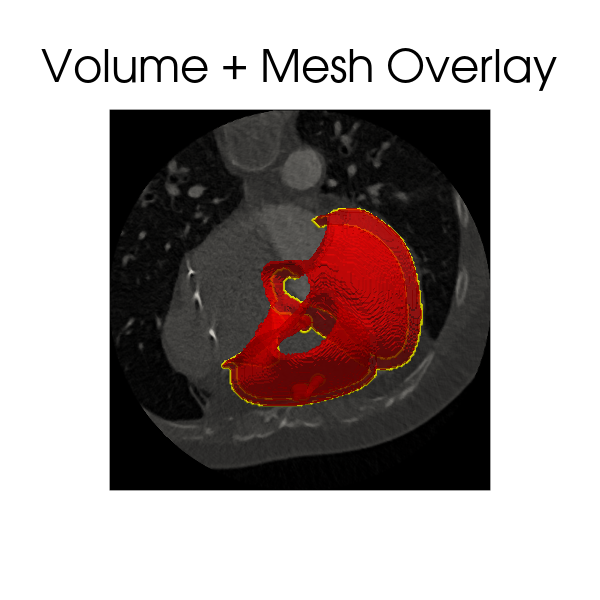

Creating 3D overlay...


KeyError: 'Data array (volume_values) not present in this dataset.'

In [47]:
def main():
    """
    Example usage of the NiftiMeshOverlay class.
    Replace with your actual file paths.
    """

    casepath='/data_fast/Work/MS_HF_cohort/data/01/'
    time=0

    # Example file paths (replace with your actual files)
    nifti_file = f'{casepath}/0_dcm/dcm-{time:1d}.nii'  # Your NIfTI file
    mesh_file = f'{casepath}/2_motion/tracked/transformed-{time:1d}.vtk'
    print(mesh_file)
    try:
        # Create overlay object
        overlay = NiftiMeshOverlay(nifti_file, mesh_file)
        
        # PyVista visualizations
        print("Creating PyVista slice visualization...")
        overlay.plot_pyvista_slice(slice_idx=None)
        
        print("Creating 3D overlay...")
        overlay.plot_3d_overlay(volume_threshold=50)
        
        print("Launching interactive PyVista viewer...")
        overlay.interactive_slice_viewer_pyvista()
        
        # Matplotlib comparison
        print("Creating matplotlib comparison...")
        overlay.plot_matplotlib_overlay(slice_idx=50)
        
        # Sample volume data on mesh vertices
        vertex_values = overlay.sample_volume_on_mesh()
        if vertex_values is not None:
            print(f"Volume values at mesh vertices - min: {vertex_values.min():.2f}, "
                  f"max: {vertex_values.max():.2f}, mean: {vertex_values.mean():.2f}")
    
    except FileNotFoundError:
        print("Example files not found. Creating sample data for demonstration...")
        
    #     # Create sample data
    #     volume_data, sample_mesh = create_sample_data()
        
    #     # Save sample data
    #     import tempfile
    #     import os
        
    #     with tempfile.TemporaryDirectory() as temp_dir:
    #         # Save sample mesh
    #         mesh_path = os.path.join(temp_dir, "sample_mesh.vtk")
    #         sample_mesh.save(mesh_path)
            
    #         # Create sample NIfTI
    #         nifti_path = os.path.join(temp_dir, "sample_volume.nii")
    #         nifti_img = nib.Nifti1Image(volume_data, affine=np.eye(4))
    #         nib.save(nifti_img, nifti_path)
            
    #         # Demonstrate with sample data
    #         overlay = NiftiMeshOverlay(nifti_path, mesh_path)
    #         overlay.plot_pyvista_slice(slice_idx=32)
        
    #     print("\nFor real data, install required libraries:")
    #     print("pip install nibabel pyvista matplotlib scipy numpy")

if __name__ == "__main__":
    main()